In [3]:
import pandas as pd
import anndata as ad
import scanpy as sc


In [4]:
# 读取count文件：
count = pd.read_csv('/home/data/t180330/TNBC.ref.IL27.260115/Seurat_csv/counts.csv', index_col=0)
# 需要转置一下，因为scanpy中行名是细胞名，列名是基因名：
count = count.T
adata = ad.AnnData(count)



In [5]:

# 读取注释文件：
obs = pd.read_csv('/home/data/t180330/TNBC.ref.IL27.260115/Seurat_csv/meta.data.csv')
adata.obs = obs.set_index(obs.columns[0])
adata

AnnData object with n_obs × n_vars = 478 × 30959
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'sub_type'

In [6]:
ad_sub = adata

In [7]:
from pathlib import Path

# 假设您定义了输出文件夹
output_dir = Path("/home/data/t180330/TNBC.ref.IL27.260115/Seurat_csv")

# 然后定义了文件名
f_loom_path_scenic = output_dir / "cell_type.loom"


In [8]:
import sys
# 使用 --user 参数，强制安装到当前用户的家目录
!{sys.executable} -m pip install loompy --user


Looking in indexes: https://mirrors.aliyun.com/pypi/simple, https://pypi.mirrors.ustc.edu.cn/simple/


In [9]:
import loompy as lp

In [10]:
import numpy as np
import loompy as lp
# create basic row and column attributes for the loom file:
row_attrs = {
    "Gene": np.array(ad_sub.var_names) ,
}
col_attrs = {
    "CellID": np.array(ad_sub.obs_names) ,
    "nGene": np.array( np.sum(ad_sub.X.transpose()>0 , axis=0)).flatten() ,
    "nUMI": np.array( np.sum(ad_sub.X.transpose() , axis=0)).flatten() ,
}
lp.create( str(f_loom_path_scenic), ad_sub.X.transpose(), row_attrs, col_attrs)

In [4]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [69]:
data2 = sc.read_loom('/home/data/t180330/TNBC.ref.IL27.260115/Seurat_csv/cell_type.loom')
auc_mtx = pd.read_csv('/home/data/t180330/TNBC.ref.IL27.260115/Seurat_csv/SCENIC.csv', index_col = 'Cell')

import scanpy as sc
from pyscenic.rss import regulon_specificity_scores
from pyscenic.plotting import plot_rss
from adjustText import adjust_text


In [6]:
import pandas as pd

# 1. 读取元数据文件
# header=0 表示第一行是列名，index_col=0 表示第一列是行名(细胞ID)
anno = pd.read_csv('/home/data/t180330/TNBC.ref.IL27.260115/meta.txt', sep='\t', header=0, index_col=0)

# 2. 将 anno 中的列合并到 data2.obs 中
# R 的 cbind 是按行合并列，Pandas 对应的是直接赋值或使用 join
# 注意：这会自动根据 index (细胞ID) 对齐数据
data2.obs = data2.obs.join(anno)

# 如果 anno 的列名和 data2.obs 现有的列名有冲突，可以使用 suffixes 参数，例如：
# data2.obs = data2.obs.join(anno, rsuffix='_new')


In [7]:
data2.obs

,nGene,nUMI,sub_type
CellID,,,
CID4495_TGCGCAGAGTTACGGG_1,1026,1963,cDC2-CD1C
CID4495_CGTTCTGAGAAGATTC_1,1608,3231,cDC2-CD1C
CID4495_TCGCGAGGTAAATGAC_1,2240,6263,cDC2-CD1C
CID4495_ACGTCAATCTTCTGGC_1,1089,2329,cDC2-CD1C
CID4495_AAACGGGCAGGAATCG_1,3720,14202,cDC2-CD1C
...,...,...,...
TTGCGTCGTCCGGATC-1_9,1628,5816,cDC2-CD1C
TTGGTTTTCCCTCTCC-1_9,2295,9762,cDC3-LAMP3
TTGTTGTTCATCTCTA-1_9,2486,9633,cDC3-LAMP3


In [ ]:
import os
print("当前工作目录:", os.getcwd())



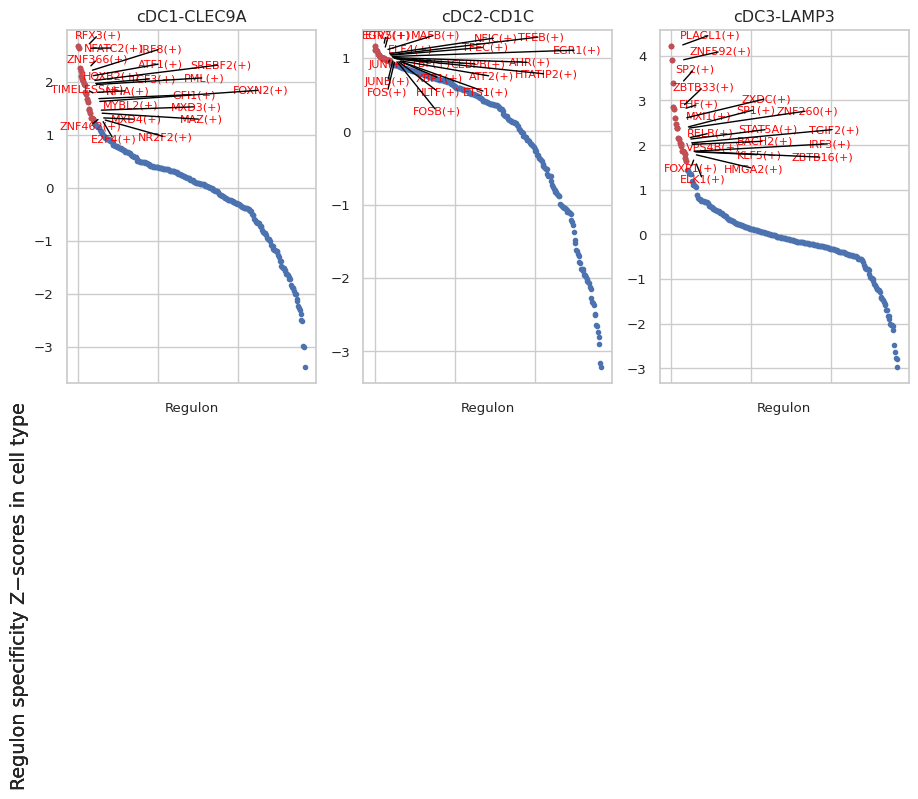

In [33]:
rss_cellType = regulon_specificity_scores(auc_mtx, data2.obs['sub_type'])
cats = sorted(list(set(data2.obs['sub_type'])))

mat = rss_cellType.to_numpy()
row_mean = np.mean(mat, axis=1, keepdims=True)
row_std = np.std(mat, axis=1, keepdims=True)
norm_mat = (mat - row_mean) / row_std

rss_cellType_norm = pd.DataFrame(norm_mat, columns=rss_cellType.columns, index=rss_cellType.index)

fig = plt.figure(figsize=(12, 12))
for c,num in zip(cats, range(1,len(cats)+1)):
    x=rss_cellType_norm.T[c]
    ax = fig.add_subplot(3,4,num)
    plot_rss(rss_cellType_norm, c, top_n=20, max_n=None, ax=ax)
    ax.set_ylim( x.min()-(x.max()-x.min())*0.05 , x.max()+(x.max()-x.min())*0.05 )
    for t in ax.texts:
      t.set_fontsize(8)
    ax.set_ylabel('')
    adjust_text(ax.texts, autoalign='xy', ha='right', va='bottom', arrowprops=dict(arrowstyle='-',color='black'), precision=0.001)
    fig.text(0.00, 0.5, 'Regulon specificity Z−scores in cell type', ha='center', va='center', rotation='vertical', size='x-large')
plt.tight_layout()
plt.rcParams.update({
    'figure.autolayout': True,
    'figure.titlesize': 'large' ,
    'axes.labelsize': 'medium',
    'axes.titlesize':'large',
    'xtick.labelsize':'medium',
    'ytick.labelsize':'medium'
})
plt.savefig('plots - GSE115978 - rss.pdf', format='pdf', bbox_inches='tight')


In [66]:
output_dir = "/home/data/t180330/data_transfer/"
output_file = os.path.join(output_dir, 'celltype_specific_regulators.csv')
# 直接对转置后的结果保存
rss_cellType_norm.T.to_csv('celltype_specific_regulators_transposed.csv')

print(f"已保存至: {output_file}")

已保存至: /home/data/t180330/data_transfer/celltype_specific_regulators.csv


In [39]:
data2.obs

,nGene,nUMI,sub_type
CellID,,,
CID4495_TGCGCAGAGTTACGGG_1,1026,1963,cDC2-CD1C
CID4495_CGTTCTGAGAAGATTC_1,1608,3231,cDC2-CD1C
CID4495_TCGCGAGGTAAATGAC_1,2240,6263,cDC2-CD1C
CID4495_ACGTCAATCTTCTGGC_1,1089,2329,cDC2-CD1C
CID4495_AAACGGGCAGGAATCG_1,3720,14202,cDC2-CD1C
...,...,...,...
TTGCGTCGTCCGGATC-1_9,1628,5816,cDC2-CD1C
TTGGTTTTCCCTCTCC-1_9,2295,9762,cDC3-LAMP3
TTGTTGTTCATCTCTA-1_9,2486,9633,cDC3-LAMP3


In [72]:
from pyscenic.export import add_scenic_metadata
from pyscenic.cli.utils import load_signatures

adjacencies = pd.read_csv("/home/data/t180330/TNBC.ref.IL27.260115/Seurat_csv/grn.output.tsv", index_col=False, sep='\t')
exprMat = data2.to_df()
sig = load_signatures('/home/data/t180330/TNBC.ref.IL27.260115/Seurat_csv/reg.csv')
data2 = add_scenic_metadata(data2, auc_mtx, sig)

tmpda = data2.var.copy(deep=True)
tmpda.columns = tmpda.columns.str.replace('Regulon(', '',regex=False)
tmpda.columns = tmpda.columns.str.replace('))', ')',regex=False)
regulons = {}
for i,r in tmpda.items():
    regulons[i] =  list(r[r==True].index.values)



Create regulons from a dataframe of enriched features.
Additional columns saved: []


In [73]:
list(regulons)[:5]

['ADNP2(+)', 'AHR(+)', 'ARID3A(+)', 'ARID5A(+)', 'ARID5B(+)']

In [74]:
sel_reg = "ZXDC(+)"
sel_trg = set(regulons[sel_reg])

In [75]:
print(f"number of target genes for '{sel_reg}': {len(sel_trg)}")

number of target genes for 'ZXDC(+)': 24


In [121]:
dedf = pd.read_csv('/home/data/t180330/TNBC.ref.IL27.260115/dedf.csv', index_col=0)

In [122]:
dedf

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
BIRC32,4.431278e-119,4.384860,0.980,0.369,1.371879e-114,cDC3-LAMP3,BIRC3
LAMP31,2.447170e-92,3.518375,0.980,0.042,7.576194e-88,cDC3-LAMP3,LAMP3
FSCN1,7.045216e-85,3.918969,0.857,0.142,2.181128e-80,cDC3-LAMP3,FSCN1
MARCKSL12,3.373702e-79,3.856902,1.000,0.366,1.044465e-74,cDC3-LAMP3,MARCKSL1
RAB9A,2.400409e-77,2.497331,0.816,0.251,7.431425e-73,cDC3-LAMP3,RAB9A
...,...,...,...,...,...,...,...
CRIP12,2.324985e-08,1.427715,0.551,0.252,7.197920e-04,cDC3-LAMP3,CRIP1
TNFAIP2,2.406626e-08,1.142989,0.714,0.519,7.450674e-04,cDC3-LAMP3,TNFAIP2
TMEM176A,1.002962e-07,1.249067,0.735,0.463,3.105070e-03,cDC3-LAMP3,TMEM176A
MALAT1,1.952164e-07,1.142013,1.000,0.996,6.043704e-03,cDC3-LAMP3,MALAT1


In [123]:
print(f"> number of DEGs per cell type: \n\n{dedf.cluster.value_counts()}")

> number of DEGs per cell type: 

cDC3-LAMP3    120
Name: cluster, dtype: int64


In [124]:
sel_subsets = {}

for cell_type in dedf.cluster.unique().tolist():
    de_genes = dedf.query(f"cluster == '{cell_type}'").gene.unique().tolist()
    sel_subsets[cell_type] = sel_trg & set(de_genes)

In [125]:
sel_cell_types = 'cDC3-LAMP3'

In [126]:
target_gene_df = pd.DataFrame({ct: {tg: 1 for tg in tgs} for ct, tgs in sel_subsets.items() if ct in sel_cell_types})
target_gene_df[target_gene_df.isna()] = 0

# get fractions
target_gene_df = (target_gene_df.T / target_gene_df.sum(axis=1)).T

# add source and target columns
target_gene_df.insert(0, 'target', target_gene_df.index.tolist())
target_gene_df = target_gene_df.reset_index(drop=True)
target_gene_df.insert(0, 'source', sel_reg)

In [127]:
target_gene_df

,source,target,cDC3-LAMP3
0,ZXDC(+),IL15,1.0
1,ZXDC(+),TBC1D4,1.0


In [128]:
target_gene_df.to_csv(f'{sel_reg}_for_cytoscape.csv')

In [129]:
import pyscenic
print(pyscenic.__version__)

0.12.1
